### Importing the helper scripts used before

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

import preprocessing as pp
import encoding as enc

### Preparing the data

In [3]:
df = pp.clean(pp.load_raw())

price = df['SalePrice']
price_class = enc.make_target(df)

X = enc.encode_features(df.drop(columns=enc.target_cols, errors='ignore'))

imputer = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns, index=X.index)

print(X.shape)

(2930, 222)


### We use `Min-max` to fit each column in the interval [0,1]. This will be useful as PCA and k-means works with distance and variance.

#### For example, a column like `Lot Area` would with values of tens of thousand would dominate a column like `Overall Qual` that goes only from 1-10 only because the unit of measurement is bigger

In [4]:
scaler = MinMaxScaler()
X_mm = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

X_mm.describe().T[['min', 'max']].head()

,min,max
Lot Frontage,0.0,1.0
Lot Area,0.0,1.0
Lot Shape,0.0,1.0
Land Slope,0.0,1.0
Overall Qual,0.0,1.0


### Now we will apply PCA

In [7]:
pca_full = PCA(random_state=42)
pca_full.fit(X_mm)

explained = pd.DataFrame({
    'PC': [f'PC{i + 1}' for i in range(len(pca_full.explained_variance_ratio_))],
    'variance': pca_full.explained_variance_ratio_.round(4),
    'cumulative': np.cumsum(pca_full.explained_variance_ratio_).round(4)
})
display(explained.head(15))

,PC,variance,cumulative
0,PC1,0.1313,0.1313
1,PC2,0.0860,0.2172
2,PC3,0.0545,0.2718
3,PC4,0.0416,0.3134
4,PC5,0.0355,0.3490
5,PC6,0.0303,0.3793
6,PC7,0.0294,0.4087
7,PC8,0.0282,0.4369
8,PC9,0.0274,0.4643
9,PC10,0.0240,0.4883


### Now let's check how many components to achieve 98%, 95%, 90% and 80%

In [ ]:
thresholds = [0.98, 0.95, 0.90, 0.80]
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_components = {t: int(np.argmax(cum_var >= t) + 1) for t in thresholds}

display(pd.DataFrame({
    'variance kept': [f'{int(t * 100)}%' for t in thresholds],
    'n_components': [n_components[t] for t in thresholds],
    'original features': X.shape[1]
}))

,variance kept,n_components,original features
0,98%,115,222
1,95%,83,222
2,90%,60,222
3,80%,37,222


### The variance is spread over many components. This is expected as most of our columns are one-hot columns and they don't offer too much information

-----

### Let's graph the cummulative variance

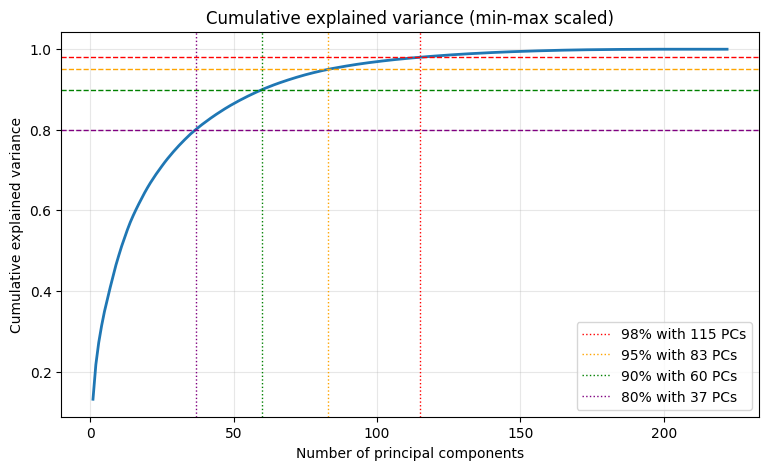

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, linewidth=2)

for t, color in zip(thresholds, ['red', 'orange', 'green', 'purple']):
    plt.axhline(t, color=color, linestyle='--', linewidth=1)
    plt.axvline(n_components[t], color=color, linestyle=':', linewidth=1,
                label=f'{int(t * 100)}% with {n_components[t]} PCs')

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance (min-max scaled)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### We notice the curve grows exponentially, gaining a lot of variance at the start, then slowing down as more components are introduced.

---

### Helper functions for PCA and elbow

In [11]:
def reduce(X_scaled, threshold):
    pca = PCA(n_components=threshold, random_state=42)
    Z = pca.fit_transform(X_scaled)
    return pca, Z


def elbow(Z, k_range=range(2, 11)):
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
        rows.append({
            'k': k,
            'inertia': km.inertia_,
            'silhouette': silhouette_score(Z, km.labels_)
        })
    return pd.DataFrame(rows)


reduced = {t: reduce(X_mm, t) for t in thresholds}
elbows = {t: elbow(reduced[t][1]) for t in thresholds}

### Elbow method

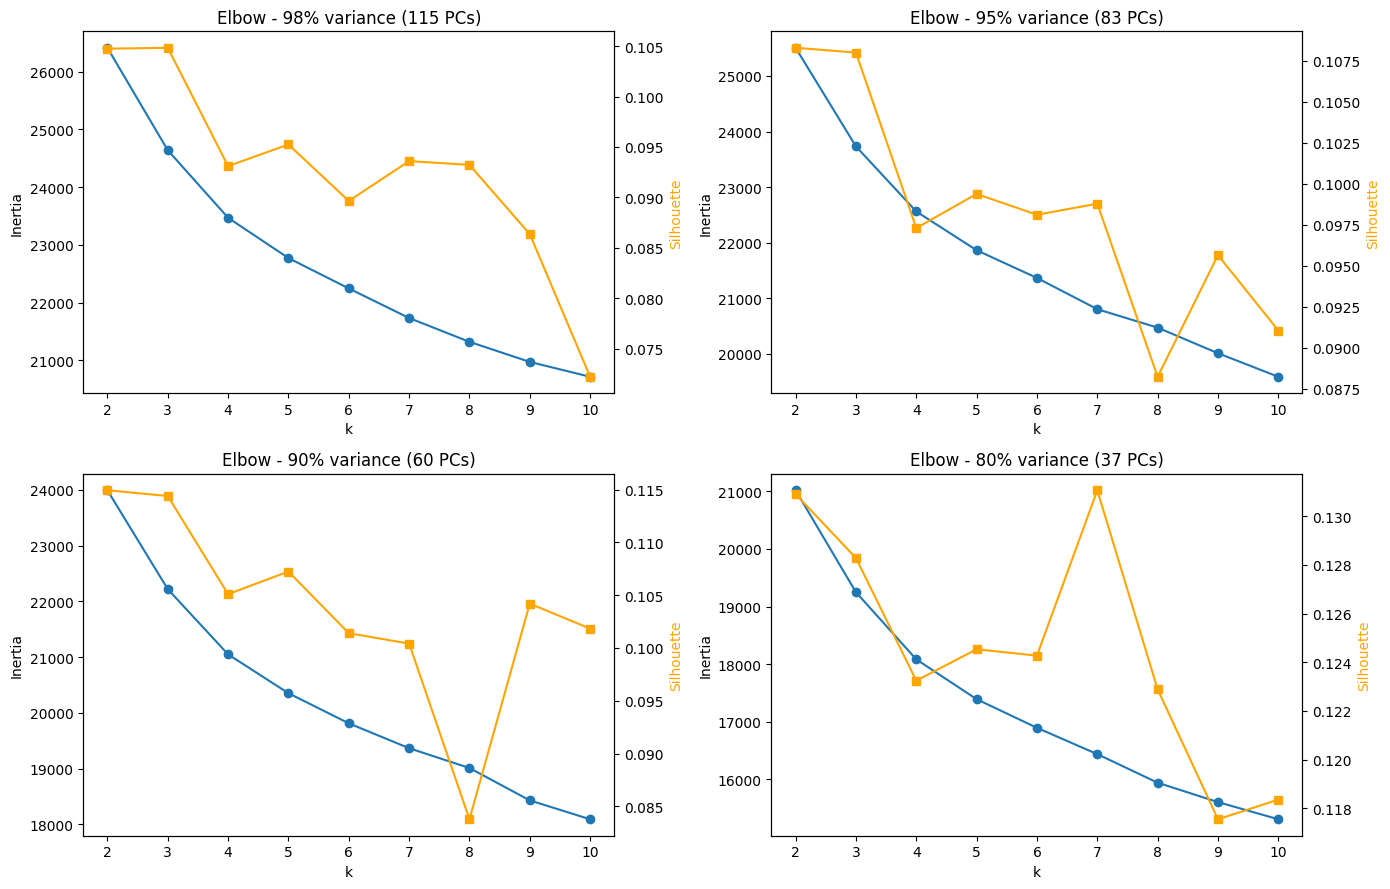

98%                   95%                   90%             \
      inertia silhouette    inertia silhouette    inertia silhouette   
k                                                                      
2   26413.767      0.105  25506.327      0.108  23992.182      0.115   
3   24639.658      0.105  23732.574      0.108  22219.491      0.114   
4   23468.979      0.093  22562.066      0.097  21049.867      0.105   
5   22771.522      0.095  21865.083      0.099  20353.208      0.107   
6   22245.438      0.090  21367.002      0.098  19813.390      0.101   
7   21732.749      0.094  20805.182      0.099  19367.306      0.100   
8   21320.099      0.093  20473.049      0.088  19011.946      0.084   
9   20972.414      0.086  20012.559      0.096  18431.177      0.104   
10  20715.164      0.072  19589.601      0.091  18092.879      0.102   

          80%             
      inertia silhouette  
k                         
2   21018.481      0.131  
3   19248.175      0.128  
4   18081.874      0.123  
5   17390.377      0.125  
6   16892.918      0.124  
7   16436.063      0.131  
8   15939.516      0.123  
9   15602.870      0.118  
10  15304.785      0.118

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

for a, t in zip(ax.ravel(), thresholds):
    e = elbows[t]
    a.plot(e['k'], e['inertia'], marker='o')
    a.set_title(f"Elbow - {int(t * 100)}% variance ({n_components[t]} PCs)")
    a.set_xlabel("k")
    a.set_ylabel("Inertia")

    # silhouette on a second axis, to see both criteria together
    a2 = a.twinx()
    a2.plot(e['k'], e['silhouette'], marker='s', color='orange')
    a2.set_ylabel("Silhouette", color='orange')

plt.tight_layout()
plt.show()

display(pd.concat({f'{int(t * 100)}%': elbows[t].set_index('k') for t in thresholds}, axis=1).round(3))

#### The inertia always goes down when k grows, so we look for the elbow point, after which adding a cluster does not help much anymore. The biggest drops are from k=2 to k=3 and k=3 to k=4, after that the curve flattens, so the elbow is around k=3.

#### The silhouette is low for every k (0.07-0.13). The houses do not form clearly separated groups, they are more like one continuous cloud. k-means will still split it, but the borders between clusters are soft.

#### The curves look the same for all four thresholds, only the absolute inertia is smaller with fewer PCs

---

### Let's plot the sillhouettes

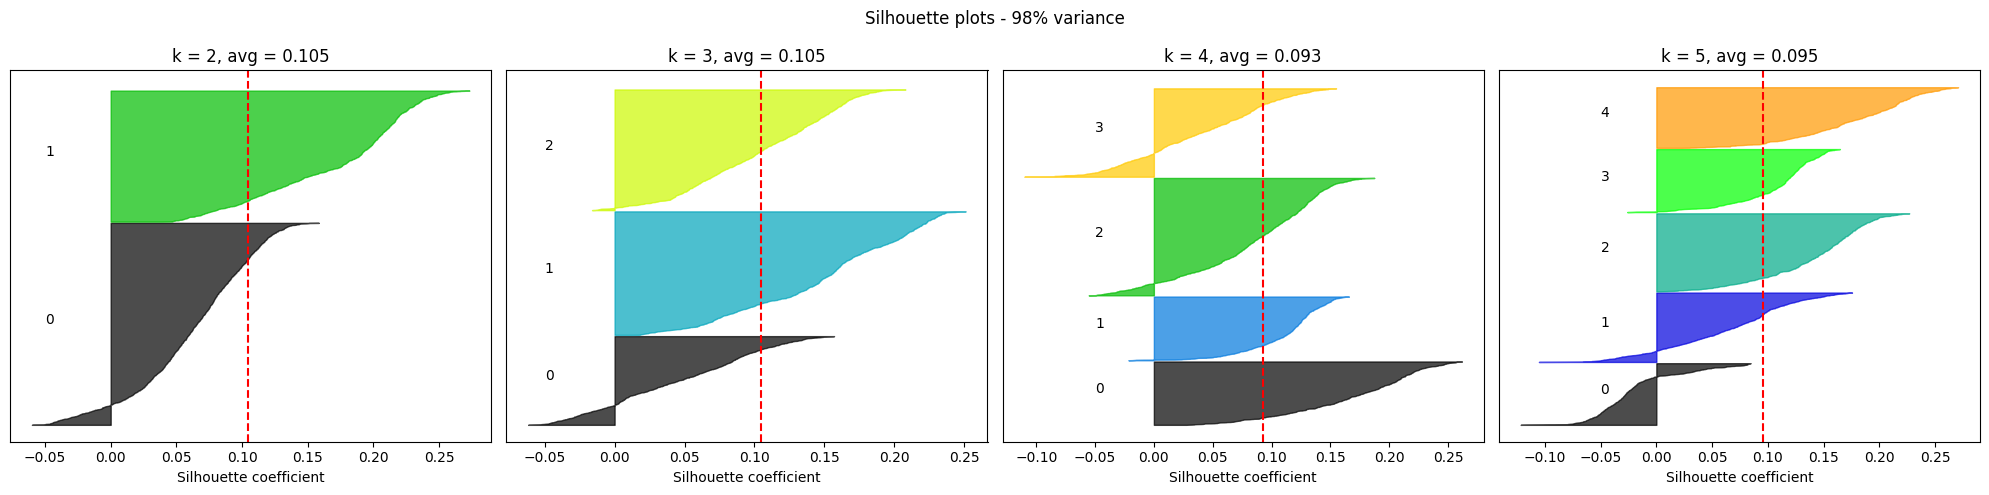

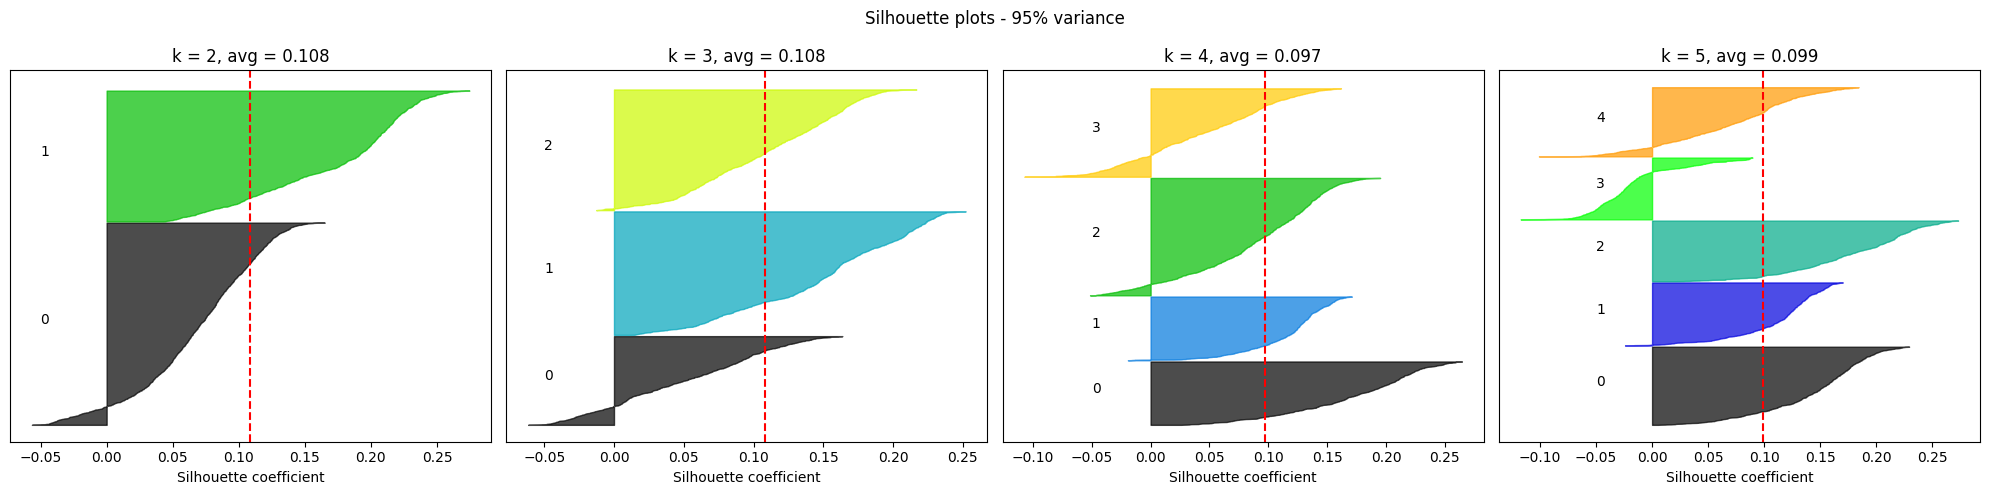

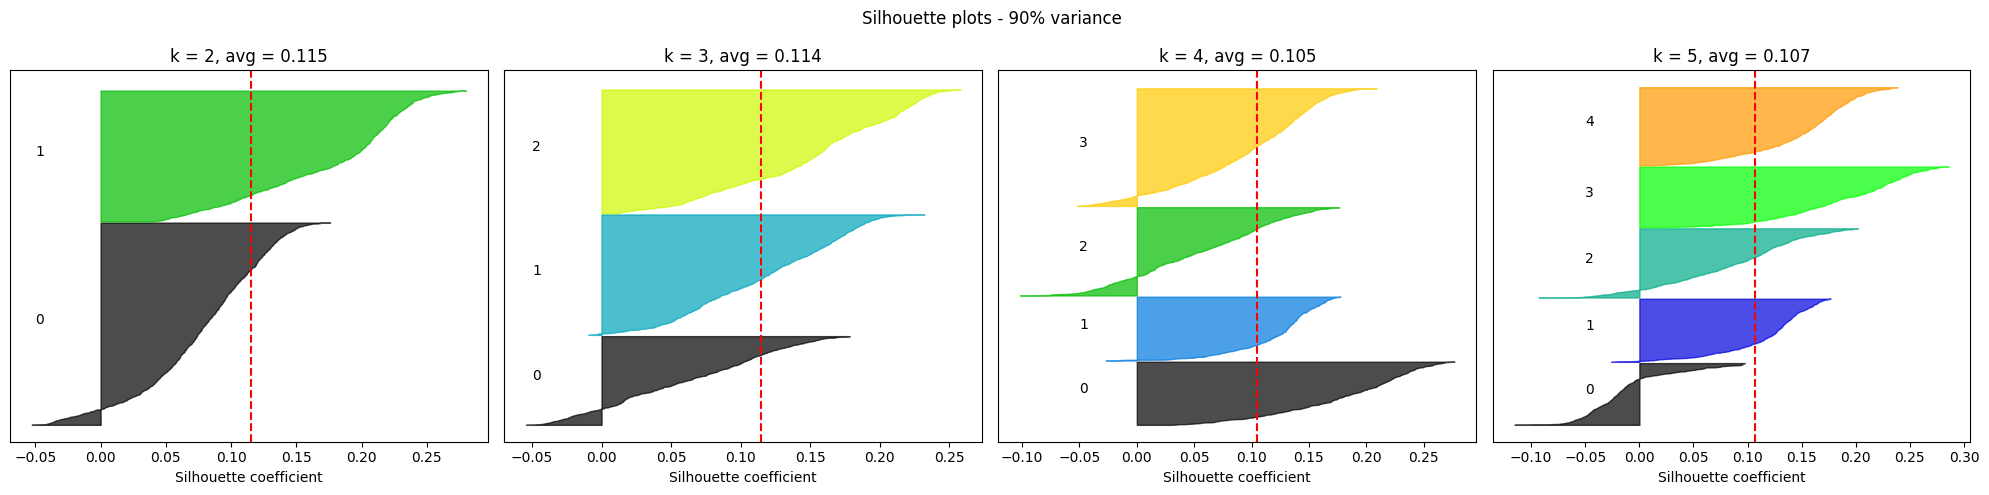

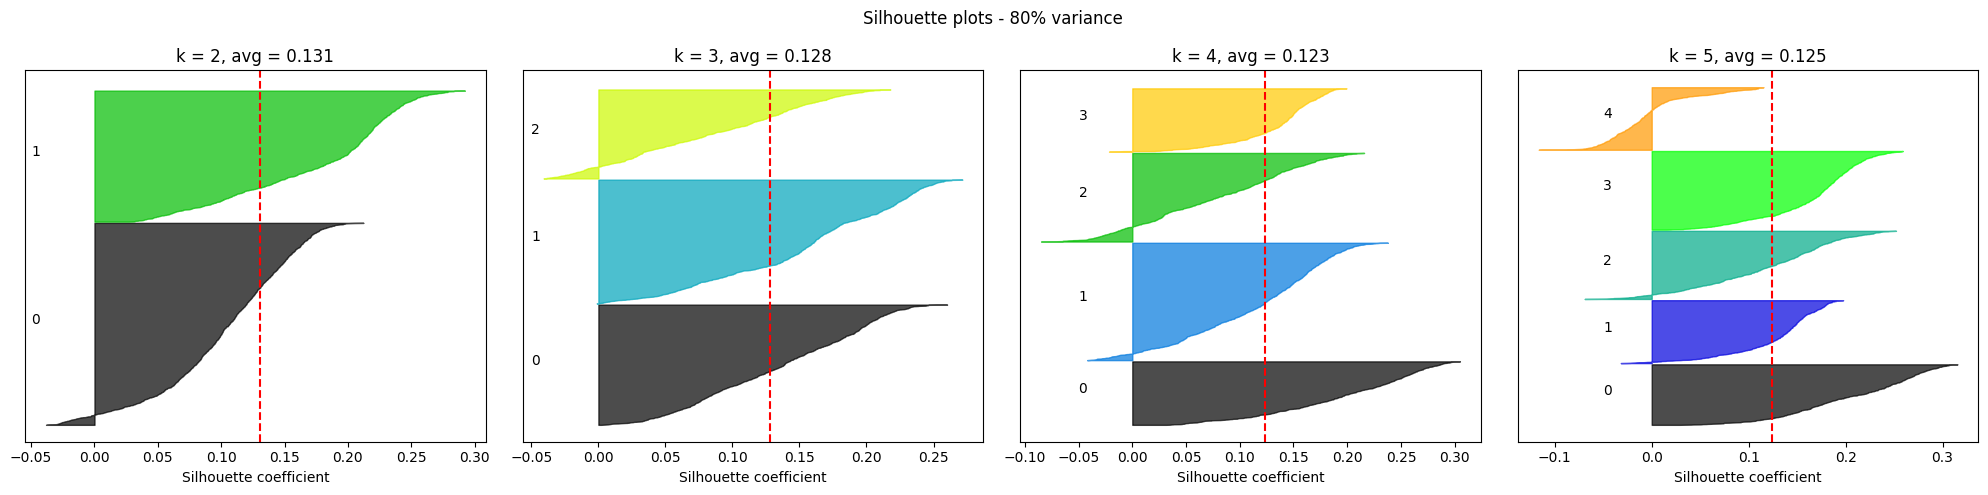

In [ ]:
def silhouette_plots(Z, k_values, title=''):
    fig, ax = plt.subplots(1, len(k_values), figsize=(5 * len(k_values), 5), sharey=True)

    for a, k in zip(ax, k_values):
        labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
        values = silhouette_samples(Z, labels)
        avg = values.mean()

        y_low = 10
        for c in range(k):
            vals = np.sort(values[labels == c])
            y_up = y_low + len(vals)
            a.fill_betweenx(np.arange(y_low, y_up), 0, vals,
                            color=cm.nipy_spectral(c / k), alpha=0.7)
            a.text(-0.05, y_low + len(vals) / 2, str(c))
            y_low = y_up + 10

        a.axvline(avg, color='red', linestyle='--')
        a.set_title(f"k = {k}, avg = {avg:.3f}")
        a.set_xlabel("Silhouette coefficient")
        a.set_yticks([])

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


silhouette_plots(reduced[0.98][1], [2, 3, 4, 5], "Silhouette plots - 98% variance")
silhouette_plots(reduced[0.95][1], [2, 3, 4, 5], "Silhouette plots - 95% variance")
silhouette_plots(reduced[0.90][1], [2, 3, 4, 5], "Silhouette plots - 90% variance")
silhouette_plots(reduced[0.80][1], [2, 3, 4, 5], "Silhouette plots - 80% variance")

### Each color is a cluster and each horizontal line represents a house and its sillhouete. The red line shows the average

#### With k=2 and k=3 we have around the same average, but we have less negative values with k=3. Because of this and the analysis from the elbow points we choose k=3.

---

### We train k-means with k=3 and scatter on PC1/PC2

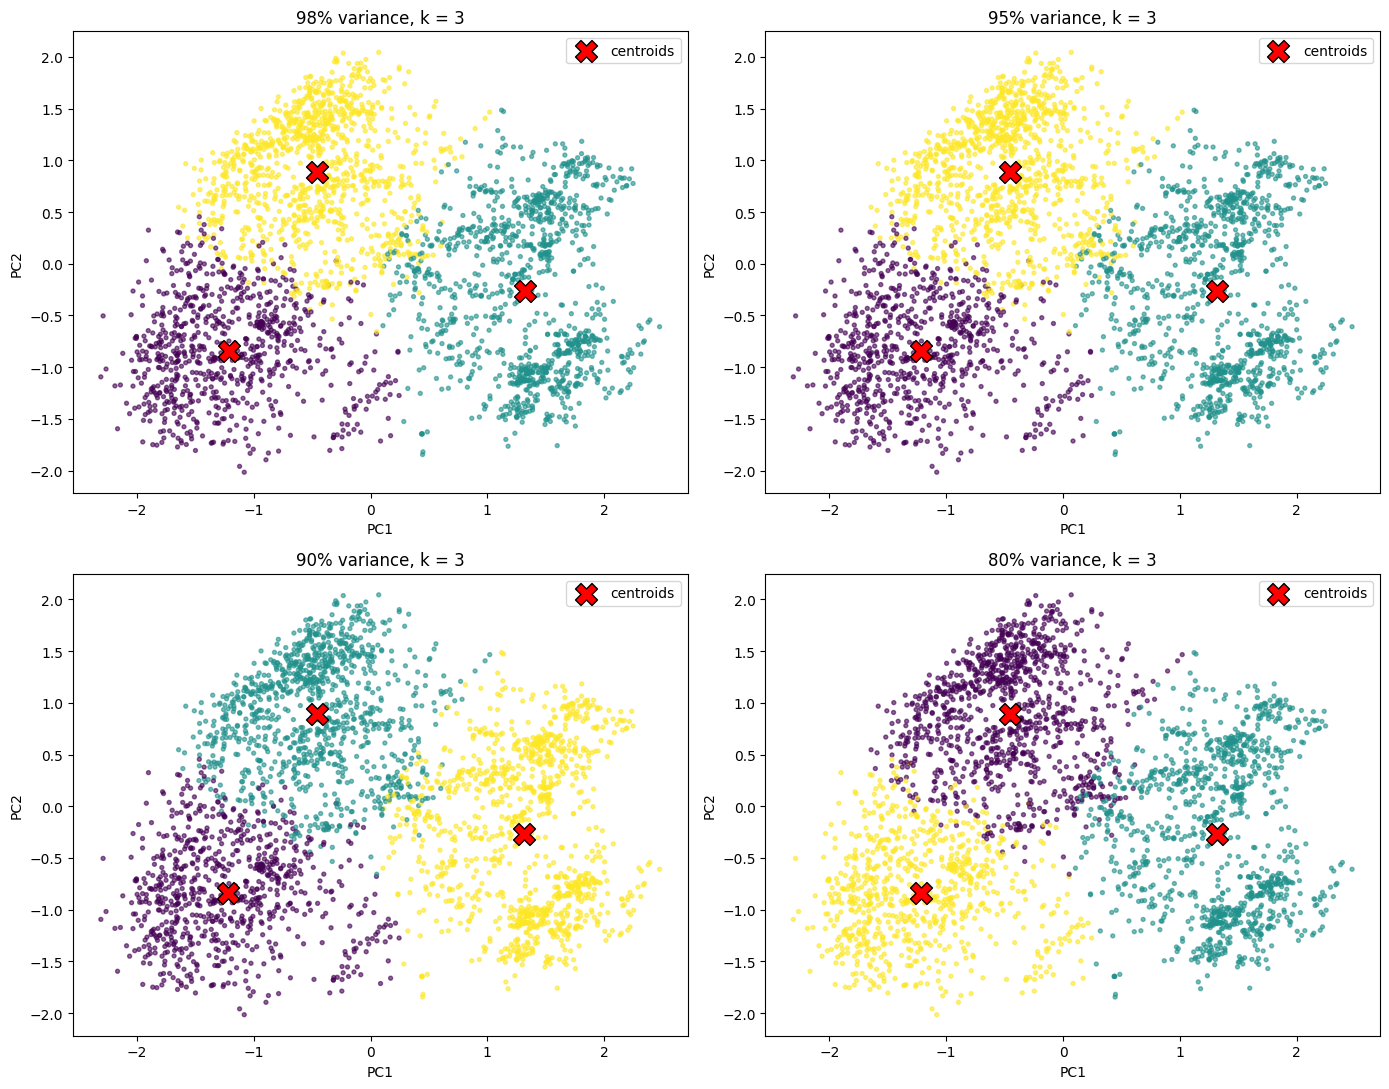

In [15]:
best_k = 3


def fit_kmeans(Z, k=best_k):
    return KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)


def cluster_scatter(a, Z, km, title):
    # first two PCs, coloured by cluster, centroids as red X
    a.scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap='viridis', s=8, alpha=0.6)
    a.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
              c='red', marker='X', s=250, edgecolor='black', label='centroids')
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
    a.set_title(title)
    a.legend()


models = {t: fit_kmeans(reduced[t][1]) for t in thresholds}

fig, ax = plt.subplots(2, 2, figsize=(14, 11))
for a, t in zip(ax.ravel(), thresholds):
    cluster_scatter(a, reduced[t][1], models[t], f"{int(t * 100)}% variance, k = {best_k}")
plt.tight_layout()
plt.show()

#### K-means was trained on the PCA space, so the centroids are PCA coordinates themselves. 

---

### Let's check if we have differences between the thresholds

In [16]:
base = models[0.98].labels_
display(pd.DataFrame({
    'threshold': [f'{int(t * 100)}%' for t in thresholds],
    'silhouette': [silhouette_score(reduced[t][1], models[t].labels_) for t in thresholds],
    'ARI vs 98%': [adjusted_rand_score(base, models[t].labels_) for t in thresholds]
}).round(3))

,threshold,silhouette,ARI vs 98%
0,98%,0.105,1.000
1,95%,0.108,1.000
2,90%,0.114,0.996
3,80%,0.128,0.994


#### The 4 clusterings are basically identical.

#### This is because k-means is driven by the directions with the largest variance (being the first PCs) that all of them share. Dropping the components going from 98% variance to 80% have very little variance, so they don't move the distances between the houses that much

#### We can also observe that the sillhouette grows with fewer PCs, because the dropped components are mostly noise. 

#### From the information above we conclude that 80% gives the same clusters as 98% with 3x less dimensions

---

### Let's try to log-transform areas and monetary values

In [17]:
log_cols = [
    'Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF',
    'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Garage Area',
    'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val'
]

display(X[log_cols].skew().sort_values(ascending=False).round(2).head(10))

X_log = X.copy()
X_log[log_cols] = np.log1p(X_log[log_cols])  

Misc Val           22.00
Pool Area          16.94
Lot Area           12.82
Low Qual Fin SF    12.12
3Ssn Porch         11.40
BsmtFin SF 2        4.14
Enclosed Porch      4.01
Screen Porch        3.96
Mas Vnr Area        2.63
Open Porch SF       2.54
dtype: float64

##### We ignored columns that wouldn't make sense to log-transform, like `Overall Qual`

#### We notice that some columns are heavily skewed. For example, `Misc Val` has a skew of 22, because almost all houses (>90%) have `Misc Val` = 0.

In [18]:
variants = {
    'min-max': MinMaxScaler().fit_transform(X),
    'standard': StandardScaler().fit_transform(X),
    'log + min-max': MinMaxScaler().fit_transform(X_log),
    'log + standard': StandardScaler().fit_transform(X_log),
}

rows = []
variant_models = {}
for name, Xs in variants.items():
    pca, Z = reduce(Xs, 0.98)
    km = fit_kmeans(Z)
    variant_models[name] = (Z, km)
    rows.append({
        'scaling': name,
        'n_components (98%)': pca.n_components_,
        'PC1 variance': pca.explained_variance_ratio_[0],
        'silhouette': silhouette_score(Z, km.labels_),
        'ARI vs min-max': adjusted_rand_score(variant_models['min-max'][1].labels_, km.labels_)
    })

display(pd.DataFrame(rows).round(3))

,scaling,n_components (98%),PC1 variance,silhouette,ARI vs min-max
0,min-max,115,0.131,0.105,1.000
1,standard,161,0.074,0.049,0.753
2,log + min-max,116,0.129,0.103,0.934
3,log + standard,159,0.074,0.042,0.412


#### We observe that applying log alongside min-max doesn't improve the model, so we stick to min-max. Aside from that, standard and log+standard give even worse results

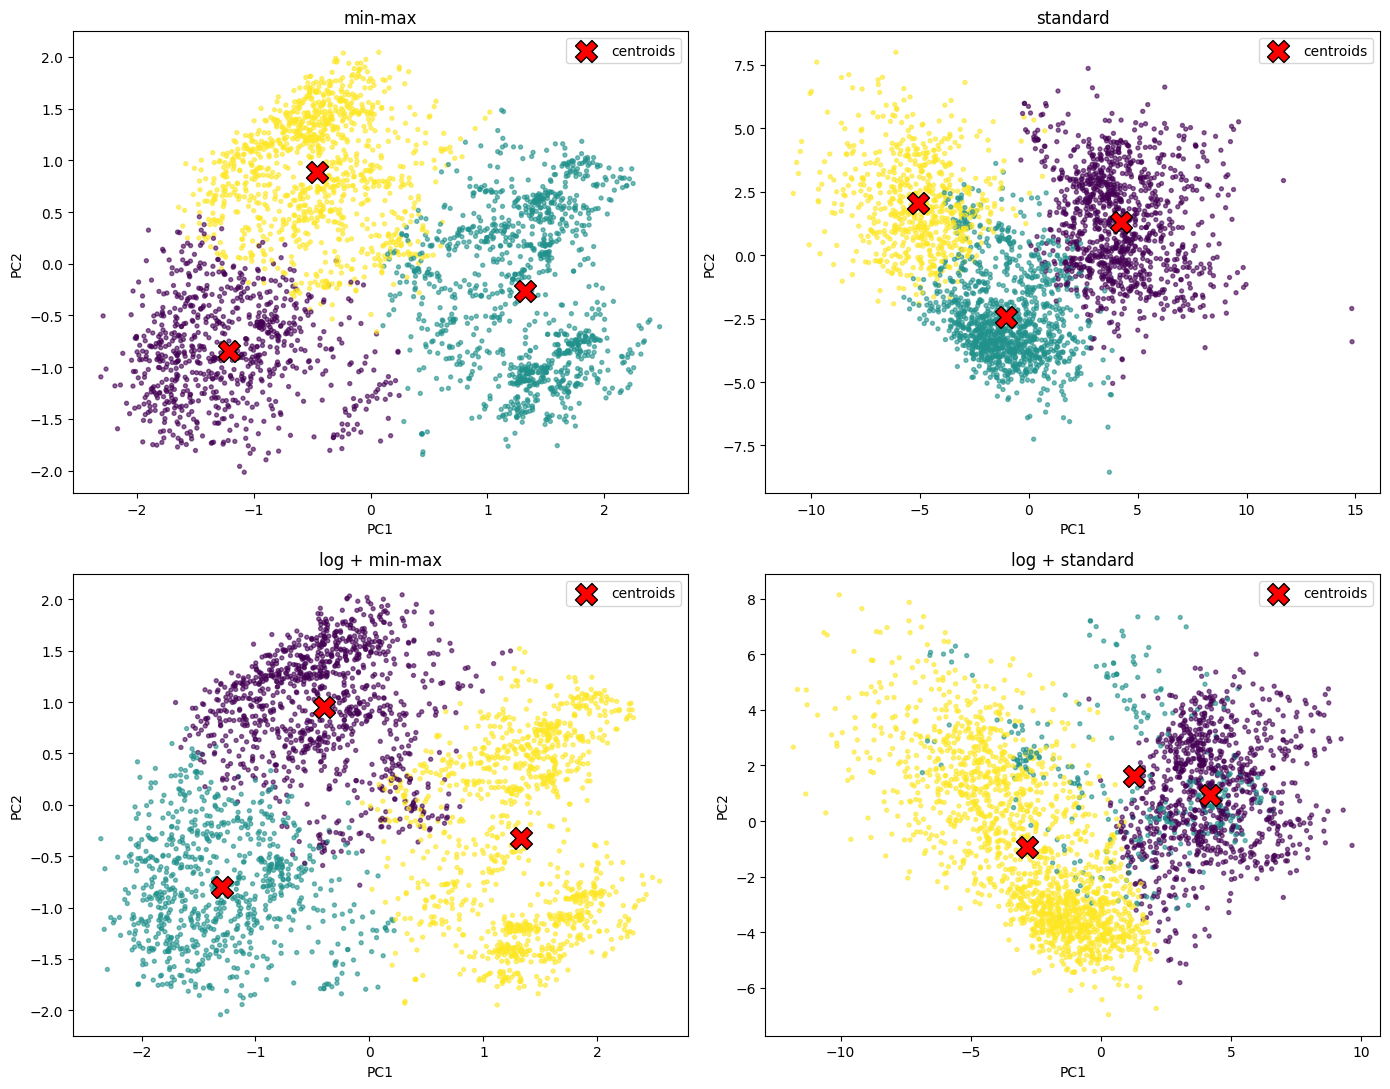

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
for a, (name, (Z, km)) in zip(ax.ravel(), variant_models.items()):
    cluster_scatter(a, Z, km, name)
plt.tight_layout()
plt.show()

#### `min-max` is clearly better than the others

---

### Loadings

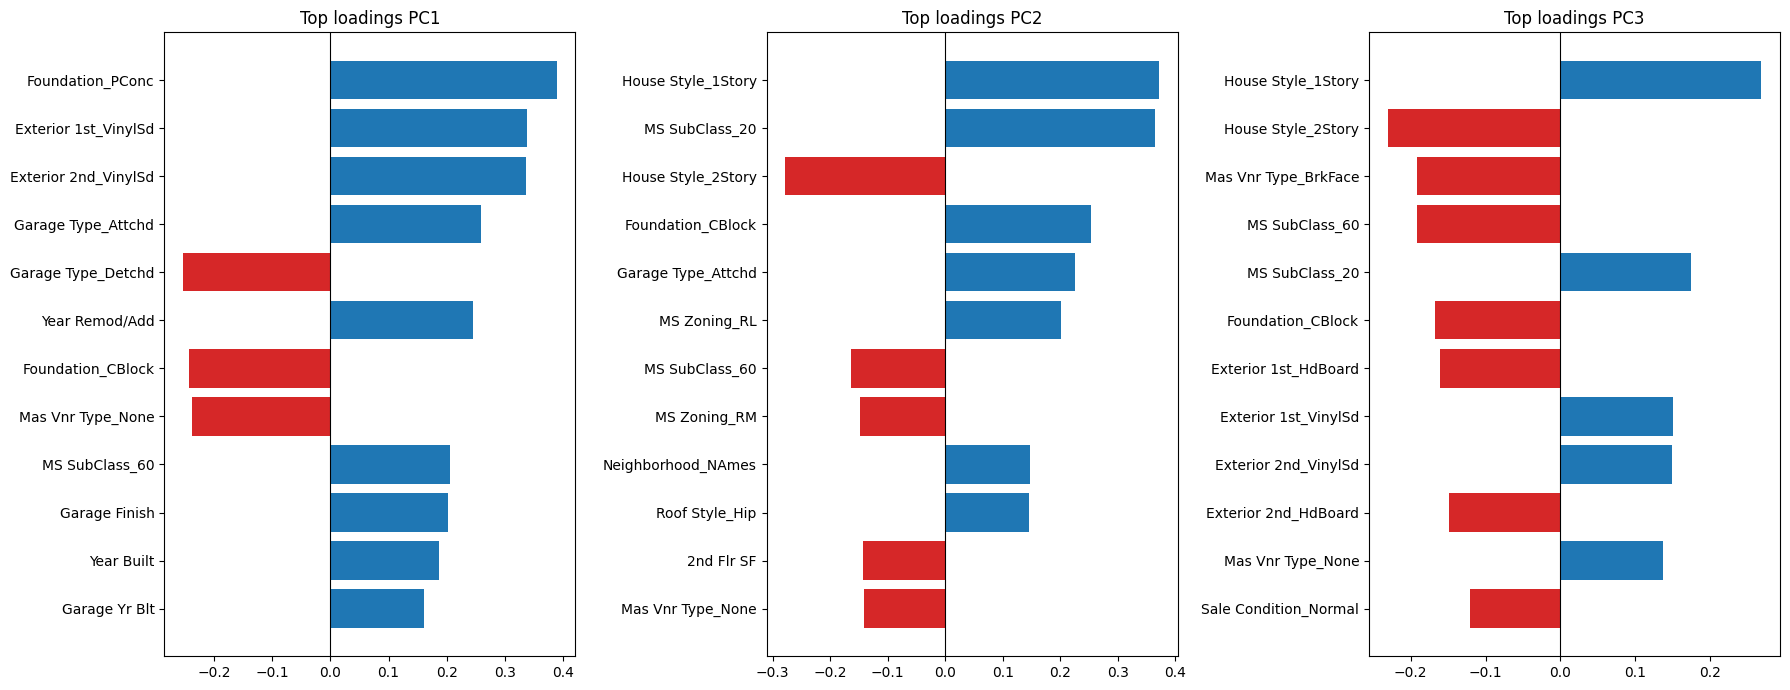

In [20]:
pca_98, Z_98 = reduced[0.98]
km_98 = models[0.98]

loadings = pd.DataFrame(
    pca_98.components_.T * np.sqrt(pca_98.explained_variance_),
    index=X.columns,
    columns=[f'PC{i + 1}' for i in range(pca_98.n_components_)]
)

fig, ax = plt.subplots(1, 3, figsize=(18, 7))
for a, pc in zip(ax, ['PC1', 'PC2', 'PC3']):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(12)
    a.barh(top.index[::-1], top.values[::-1],
           color=['tab:blue' if v > 0 else 'tab:red' for v in top.values[::-1]])
    a.set_title(f"Top loadings {pc}")
    a.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

### Now let's do a heatmap with loadings

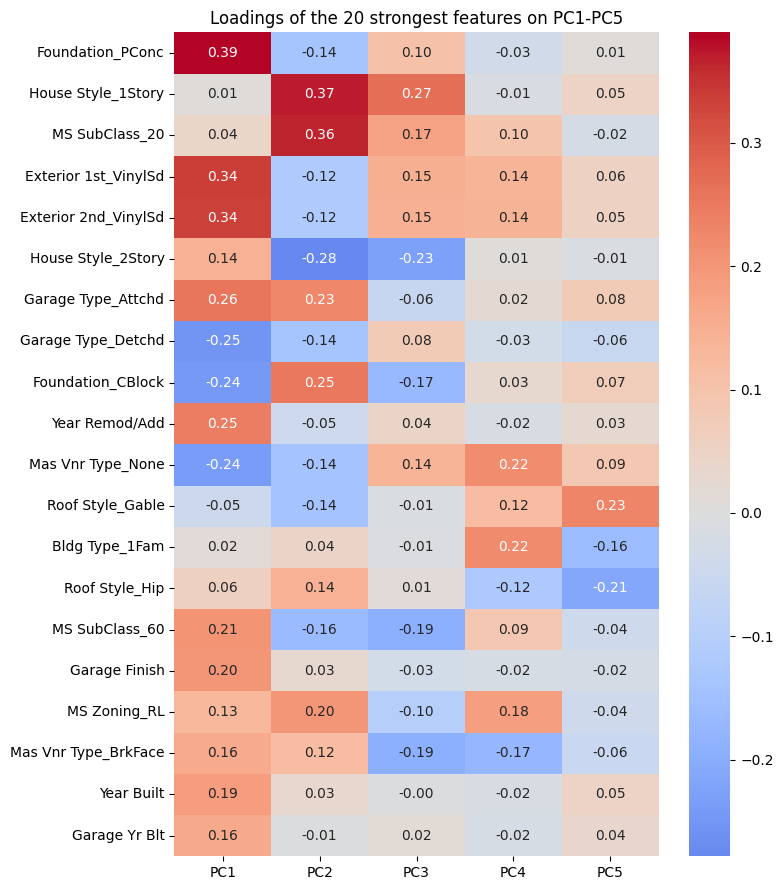

In [21]:
top_features = loadings[['PC1', 'PC2', 'PC3', 'PC4', 'PC5']].abs().max(axis=1).sort_values(ascending=False).head(20).index

plt.figure(figsize=(8, 9))
sns.heatmap(loadings.loc[top_features, ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']],
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Loadings of the 20 strongest features on PC1-PC5")
plt.tight_layout()
plt.show()

#### PC1 is basically new vs old houses - contributing to positive scores are houses built with new materials (poured concrete, vinyl siding attached garages etc.), while contributing to negative scores are houses built with old materials like cinder blocks and detached garages

#### PC2 is basically one vs two story houses

#### PC3 mixes style and exterior material, meaning architectural style

After min-max scaling, the strongest loadings are almost all one-hot columns. A 0/1 column has the
full [0, 1] range, while a column like `Gr Liv Area` has most of the houses in a small part of its range

---

### Let's see what type of houses are in each cluster

In [25]:
profile = df.copy()
profile['Cluster'] = km_98.labels_

profile_cols = ['SalePrice', 'Overall Qual', 'Year Built', 'Gr Liv Area', 'Total Bsmt SF',
                'Garage Cars', 'Full Bath', 'Lot Area']

summary = profile.groupby('Cluster')[profile_cols].median()
summary['n_houses'] = profile['Cluster'].value_counts().sort_index()
display(summary)

for c in range(best_k):
    part = profile[profile['Cluster'] == c]
    print(f"Cluster {c}")
    for col in ['Neighborhood', 'House Style', 'Foundation', 'Garage Type', 'Exterior 1st']:
        top = part[col].value_counts(normalize=True).head(3).round(2).to_dict()
        print(f"  {col}: {top}")
    print()

,SalePrice,Overall Qual,Year Built,Gr Liv Area,Total Bsmt SF,Garage Cars,Full Bath,Lot Area,n_houses
Cluster,,,,,,,,,
0,123500.0,5.0,1930.0,1316.0,756.0,1.0,1.0,7449.0,781
1,220000.0,7.0,2004.0,1666.0,1234.0,2.0,2.0,9965.0,1087
2,146150.0,5.0,1965.0,1226.0,1040.0,2.0,1.0,9865.5,1062


Cluster 0
  Neighborhood: {'OldTown': 0.29, 'BrkSide': 0.13, 'IDOTRR': 0.12}
  House Style: {'1.5Fin': 0.36, '2Story': 0.33, '1Story': 0.22}
  Foundation: {'BrkTil': 0.39, 'CBlock': 0.36, 'PConc': 0.2}
  Garage Type: {'Detchd': 0.7, 'None': 0.15, 'Attchd': 0.11}
  Exterior 1st: {'MetalSd': 0.31, 'Wd Sdng': 0.3, 'VinylSd': 0.11}

Cluster 1
  Neighborhood: {'CollgCr': 0.21, 'NridgHt': 0.15, 'Gilbert': 0.14}
  House Style: {'1Story': 0.48, '2Story': 0.47, 'SLvl': 0.03}
  Foundation: {'PConc': 0.98, 'CBlock': 0.02, 'Wood': 0.0}
  Garage Type: {'Attchd': 0.81, 'BuiltIn': 0.14, 'Detchd': 0.03}
  Exterior 1st: {'VinylSd': 0.79, 'CemntBd': 0.07, 'HdBoard': 0.06}

Cluster 2
  Neighborhood: {'NAmes': 0.37, 'Sawyer': 0.13, 'NWAmes': 0.1}
  House Style: {'1Story': 0.74, '2Story': 0.1, 'SLvl': 0.08}
  Foundation: {'CBlock': 0.89, 'PConc': 0.08, 'Slab': 0.02}
  Garage Type: {'Attchd': 0.73, 'Detchd': 0.19, 'None': 0.03}
  Exterior 1st: {'HdBoard': 0.32, 'Plywood': 0.18, 'Wd Sdng': 0.17}



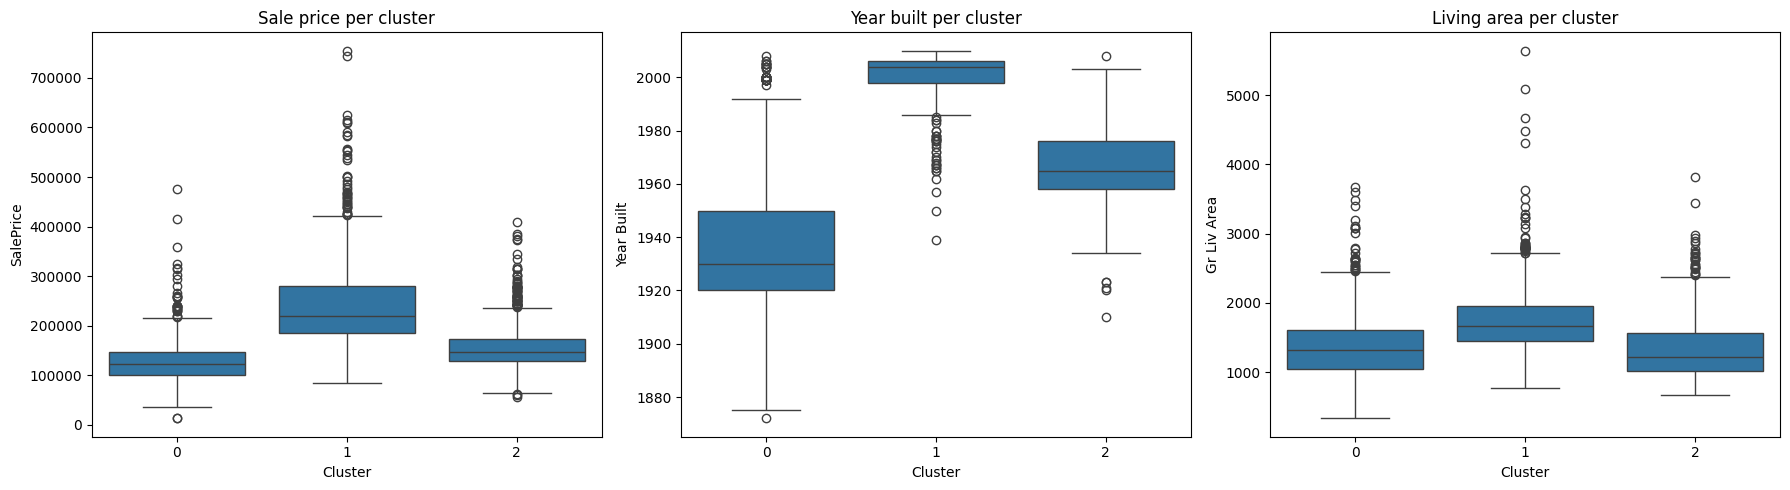

SalePrice,<100k,100-130k,130-180k,180-250k,250-400k,>=400k
Cluster,,,,,,
0,196,260,255,55,13,2
1,1,3,220,470,332,61
2,40,246,562,161,52,1


In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=profile, x='Cluster', y='SalePrice', ax=ax[0])
sns.boxplot(data=profile, x='Cluster', y='Year Built', ax=ax[1])
sns.boxplot(data=profile, x='Cluster', y='Gr Liv Area', ax=ax[2])
ax[0].set_title("Sale price per cluster")
ax[1].set_title("Year built per cluster")
ax[2].set_title("Living area per cluster")
plt.tight_layout()
plt.show()

display(pd.crosstab(profile['Cluster'], price_class).rename(columns=dict(enumerate(enc.price_labels))))

#### Cluster 0 shows old town houses, from historic neighbourhoods, with brick/tile foundation, detached garages and wood or metal siding. These houses have the lowest prices

#### Cluster 1 shows modern houses. Almost all have poured concrete foundations, vinyl siding and attached garages and come from new neighbourhoods. They have the highest quality and price. 

#### Cluster 2 shows post ww2 houses. They are mostly 1 floor ranch houses with cinder block foundations. They have prices above the old town houses, but below modern houses.


#### We can observe that the clusters follow the construction era (pre ww2, post ww2, modern), but they overlap at the 130-180k class.

---

### Let's insert some made-up houses

In [26]:
# typical house
reference = df.drop(columns=enc.target_cols, errors='ignore')
template = reference.mode().iloc[0].copy()
template.update(reference.median(numeric_only=True))


def make_house(changes):
    house = template.copy()
    for col, value in changes.items():
        house[col] = value
    return house


new_houses = pd.DataFrame([
    # new, big, expensive house in a rich neighbourhood
    make_house({'Neighborhood': 'NridgHt', 'Overall Qual': 9, 'Year Built': 2007,
                'Year Remod/Add': 2007, 'Garage Yr Blt': 2007, 'Gr Liv Area': 3000,
                'Total Bsmt SF': 1800, 'Garage Cars': 3, 'Garage Area': 800, 'Full Bath': 3,
                'Exter Qual': 'Ex', 'Kitchen Qual': 'Ex', 'Bsmt Qual': 'Ex',
                'Foundation': 'PConc', 'House Style': '2Story', 'MS SubClass': '60'}),
    # small old house from the 1920s in the old town
    make_house({'Neighborhood': 'OldTown', 'MS Zoning': 'RM', 'Overall Qual': 4,
                'Year Built': 1920, 'Year Remod/Add': 1950, 'Garage Yr Blt': 1950,
                'Gr Liv Area': 1100, 'Total Bsmt SF': 650, 'Garage Cars': 1, 'Garage Area': 240,
                'Full Bath': 1, 'Exter Qual': 'TA', 'Kitchen Qual': 'Fa', 'Bsmt Qual': 'Fa',
                'Foundation': 'BrkTil', 'House Style': '1.5Fin', 'MS SubClass': '50',
                'Garage Type': 'Detchd', 'Exterior 1st': 'Wd Sdng', 'Exterior 2nd': 'Wd Sdng',
                'Lot Area': 6000}),
    # average 1960s ranch house in North Ames
    make_house({'Neighborhood': 'NAmes', 'Overall Qual': 5, 'Year Built': 1962,
                'Year Remod/Add': 1962, 'Garage Yr Blt': 1962, 'Gr Liv Area': 1100,
                'Total Bsmt SF': 1050, 'Garage Cars': 1, 'Garage Area': 300, 'Full Bath': 1,
                'Foundation': 'CBlock', 'House Style': '1Story', 'MS SubClass': '20',
                'Exterior 1st': 'HdBoard', 'Exterior 2nd': 'HdBoard'}),
], index=['luxury new', 'old small', 'average 60s']).infer_objects()


### Now we make some predictions on the new houses

In [27]:
X_new = enc.encode_features(new_houses).reindex(columns=X.columns, fill_value=0)
X_new = pd.DataFrame(imputer.transform(X_new), columns=X.columns, index=X_new.index)
X_new_scaled = pd.DataFrame(scaler.transform(X_new), columns=X.columns, index=X_new.index)
Z_new = pca_98.transform(X_new_scaled)

new_houses['Cluster'] = km_98.predict(Z_new)
display(new_houses[['Neighborhood', 'Overall Qual', 'Year Built', 'Gr Liv Area', 'Foundation', 'Cluster']])

,Neighborhood,Overall Qual,Year Built,Gr Liv Area,Foundation,Cluster
luxury new,NridgHt,9,2007,3000,PConc,1
old small,OldTown,4,1920,1100,BrkTil,0
average 60s,NAmes,5,1962,1100,CBlock,2


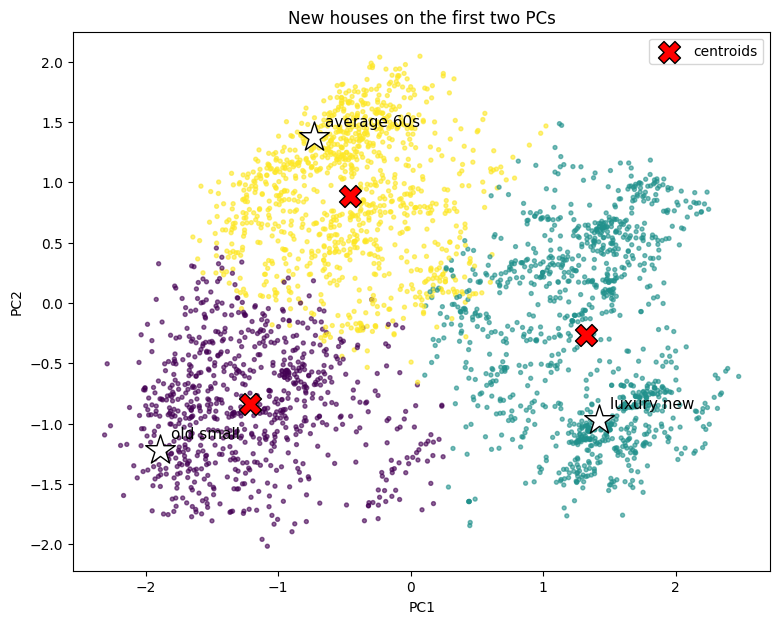

In [28]:
fig, ax = plt.subplots(figsize=(9, 7))
cluster_scatter(ax, Z_98, km_98, "New houses on the first two PCs")
ax.scatter(Z_new[:, 0], Z_new[:, 1], c='white', marker='*', s=500, edgecolor='black')
for name, (x, y) in zip(new_houses.index, Z_new[:, :2]):
    ax.annotate(name, (x, y), xytext=(8, 8), textcoords='offset points', fontsize=11)
plt.show()

#### We can observe that the houses landed in exactly the clusters that we expected them to, as seen in the table and graph

---

### Bonus a + b - 3D Interactive graphs

In [ ]:
import plotly.graph_objects as go


def plot_3d(Z, colors, title, centers=None, names=None, palette=None):
    fig = go.Figure()
    for value in sorted(np.unique(colors)):
        mask = colors == value
        fig.add_trace(go.Scatter3d(
            x=Z[mask, 0], y=Z[mask, 1], z=Z[mask, 2],
            mode='markers',
            marker=dict(size=2, color=palette[value] if palette else None),
            name=names[value] if names else f'cluster {value}'
        ))
    if centers is not None:
        fig.add_trace(go.Scatter3d(
            x=centers[:, 0], y=centers[:, 1], z=centers[:, 2],
            mode='markers', marker=dict(size=10, symbol='diamond', color='black'),
            name='centroids'
        ))
    fig.update_layout(title=title, height=650,
                      scene=dict(xaxis_title='PC1', yaxis_title='PC2', zaxis_title='PC3'))
    fig.show()

# a) one plot per clustering
for t in thresholds:
    plot_3d(reduced[t][1], models[t].labels_, f"k-means, {int(t * 100)}% variance",
            centers=models[t].cluster_centers_)

In [30]:
# b) same space, coloured by the six price classes from lab 2 (most expensive = blue)
price_palette = ['red', 'orange', 'gold', 'purple', 'green', 'blue']

plot_3d(Z_98, price_class.values, "Coloured by price class",
        names=enc.price_labels, palette=price_palette)

**a)** In 3D the cloud looks like one connected body with denser regions rather than three separate
blobs, which matches the low silhouette. k-means cuts this body with straight borders (every point goes
to the nearest centroid), so it works, but the borders are arbitrary. A density based method such as
DBSCAN would probably find one big cluster, a Gaussian Mixture Model would allow soft, elliptical clusters,
which fits better to data without clear gaps.

**b)** The price classes form a gradient mainly along PC1: expensive houses (blue/green) are on the
"new house" side, cheap ones on the other side. But the classes overlap strongly and do not match
the clusters one to one.

The reason is the different goal: XGBoost in lab 2 was told the price and picked the features that predict
it (`Overall Qual`, `Gr Liv Area`, see feature importance). PCA and k-means never see the price; they
follow the directions with the most variance, which here are the construction era and the number of floors
(see the loadings). Age is correlated with price, so the clusters are ordered by price, but size and
quality, the strongest price drivers, are not what separates the clusters.